# 🤖 Лаборатория обучения RL-агента исполнения (Maskable PPO + L2 FIFO)
Этот блокнот позволяет в реальном времени запускать, отслеживать и препарировать обучение **RL-агента микроструктурного исполнения (`MaskableActorCritic`)** поверх 10-уровневого L2 FIFO-стакана SafeTrade и сигналов триады ансамблей (`H=5s, 12s, 25s`).

⚡ Загрузка готового кэша RL-полигона (Триада H=5,12,25s): rl_triad_lob_cache_prl_72h.npz
✅ Размерность матрицы состояния рынка: (259200, 28) | Период: 2026-10-20 15:52:38+03:00 ➔ 2026-10-23 15:52:37+03:00


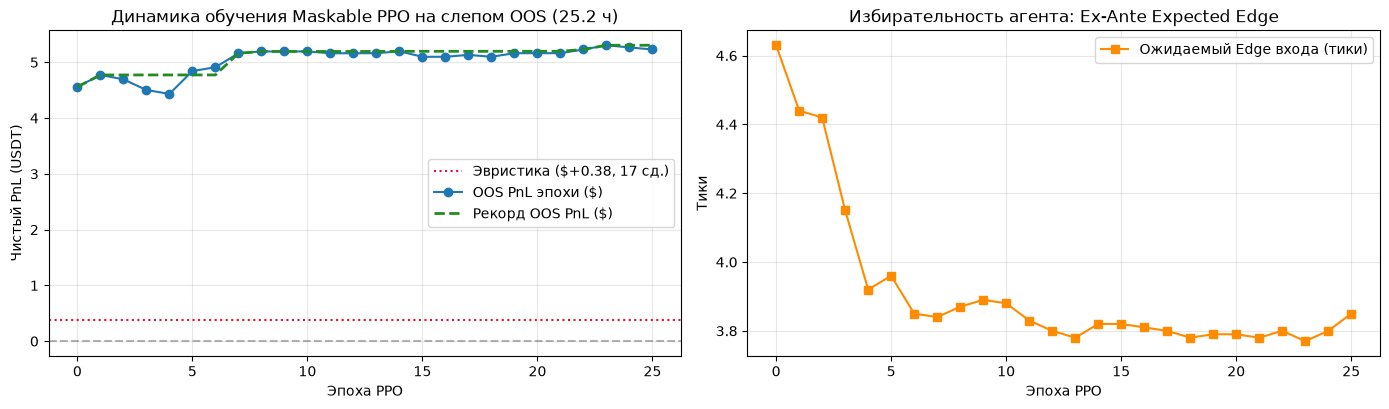

,epoch,pnl_usd,pnl_pct,oracle_pnl_usd,kpd_capture_pct,efficiency_score,exit_eff_pct,mean_mfe_ticks,mean_mae_ticks,max_dd_usd,max_dd_pct,profit_factor,trades,hours,exp_edge_ticks,critic_v_ticks,real_pnl_per_trade_usd,best_pnl_usd,best_score
0,0,4.5588,30.39,4.7857,95.26,81.69,48.4,3.25,1.72,0.3976,2.65,11.20,85,25.2,4.63,-0.03,0.0536,4.5588,81.69
1,1,4.7732,31.82,4.7857,99.74,85.53,50.0,3.16,1.73,0.3976,2.65,11.68,90,25.2,4.44,-0.03,0.0530,4.7732,85.53
2,2,4.6949,31.30,4.7857,98.10,84.12,50.5,3.05,1.76,0.3976,2.65,11.51,93,25.2,4.42,-0.02,0.0505,4.7732,85.53
3,3,4.5036,30.02,4.7857,94.11,76.08,48.2,3.07,1.85,0.5668,3.78,8.01,95,25.2,4.15,-0.13,0.0474,4.7732,85.53
4,4,4.4330,29.55,4.7857,92.63,74.89,47.2,3.05,1.88,0.5668,3.78,7.54,97,25.2,3.92,-0.15,0.0457,4.7732,85.53
5,5,4.8425,32.28,4.7857,101.19,81.81,46.7,3.04,1.88,0.5668,3.78,7.50,107,25.2,3.96,-0.19,0.0453,4.7732,85.53
6,6,4.9111,32.74,4.7857,102.62,82.97,48.1,3.05,1.84,0.5668,3.78,8.27,106,25.2,3.85,-0.20,0.0463,4.7732,85.53
7,7,5.1614,34.41,4.7857,107.85,87.20,48.9,3.05,1.78,0.5668,3.78,9.06,109,25.2,3.84,-0.25,0.0474,5.1614,87.20
8,8,5.1945,34.63,4.7857,108.54,87.75,49.8,3.04,1.77,0.5668,3.78,9.11,109,25.2,3.87,-0.34,0.0477,5.1945,87.75
9,9,5.1945,34.63,4.7857,108.54,87.75,49.8,3.04,1.77,0.5668,3.78,9.11,109,25.2,3.89,-0.35,0.0477,5.1945,87.75


In [3]:
# 📊 ЯЧЕЙКА 1: Обзор кэша полигона и кривой сходимости последнего обучения
import importlib
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)
from _tools.train_rl_execution import build_or_load_rl_cache

TAIL_HOURS = 72.0
data = build_or_load_rl_cache(coin="prl", tail_hours=TAIL_HOURS)
print(f"✅ Размерность матрицы состояния рынка: {data['X_market'].shape} | Период: {data['ts'][0]} ➔ {data['ts'][-1]}")

hist_path = Path("models/prl/rl_execution/training_history.json")
if hist_path.exists():
    h_data = json.loads(hist_path.read_text())
    df_h = pd.DataFrame(h_data["history"])
    base = h_data["baseline"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
    ax1.axhline(0.0, color="gray", ls="--", alpha=0.6)
    ax1.axhline(base["pnl_usd"], color="crimson", ls=":", label=f"Эвристика (${base['pnl_usd']:+.2f}, {base['trades']} сд.)")
    ax1.plot(df_h["epoch"], df_h["pnl_usd"], marker="o", label="OOS PnL эпохи ($)")
    ax1.plot(df_h["epoch"], df_h["best_pnl_usd"], ls="--", color="forestgreen", lw=2, label="Рекорд OOS PnL ($)")
    ax1.set_title("Динамика обучения Maskable PPO на слепом OOS (25.2 ч)")
    ax1.set_xlabel("Эпоха PPO"); ax1.set_ylabel("Чистый PnL (USDT)"); ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(df_h["epoch"], df_h["exp_edge_ticks"], marker="s", color="darkorange", label="Ожидаемый Edge входа (тики)")
    ax2.set_title("Избирательность агента: Ex-Ante Expected Edge")
    ax2.set_xlabel("Эпоха PPO"); ax2.set_ylabel("Тики"); ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    display(df_h)

In [ ]:
# 🚀 ЯЧЕЙКА 2: Запуск живого обучения RL-агента с онлайн-графиком после каждой эпохи
import importlib
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)

res = _rl_mod.train_rl_agent(
    coin="prl",
    tail_hours=72.0,
    ppo_epochs=25,
    steps_per_epoch=16384,
    live_plot=True,
)

⚡ Загрузка готового кэша RL-полигона (Триада H=5,12,25s): rl_triad_lob_cache_prl_72h.npz

📊 СРАВНЕНИЕ ПАСПОРТОВ КПД АГЕНТОВ НА СЛЕПОМ OOS (25.2 ч | Потолок Оракула: +$4.9617 = 100% КПД)
📅 Период (МСК): 2026-10-22 14:40:38+03:00 ➔ 2026-10-23 15:52:37+03:00
Метрика КПД                        | Базовый эталон (v2)        | Maskable PPO (v3)         
------------------------------------------------------------------------------------------------
Чистый PnL (USDT / % к ордеру)     | $+0.3818 (+2.55%)        | $+5.3054 (+35.37%)
Физический КПД захвата (η_capture) |  +7.70%                   | +106.93%
Интегральный индекс (Score)        |  +6.57                    | +87.04
КПД фиксации волны (η_exit от MFE) |   32.5%                   |   49.2%
Средний MFE / MAE (тики)           | 2.82т / 3.82т             | 3.05т / 1.86т
Макс. просадка MTM (MaxDD)         | $0.4235 (2.82%)         | $0.5668 (3.78%)
Profit Factor / Сделок             | PF=99.00 (17 сд.)          | PF=8.48 (111 сд.)



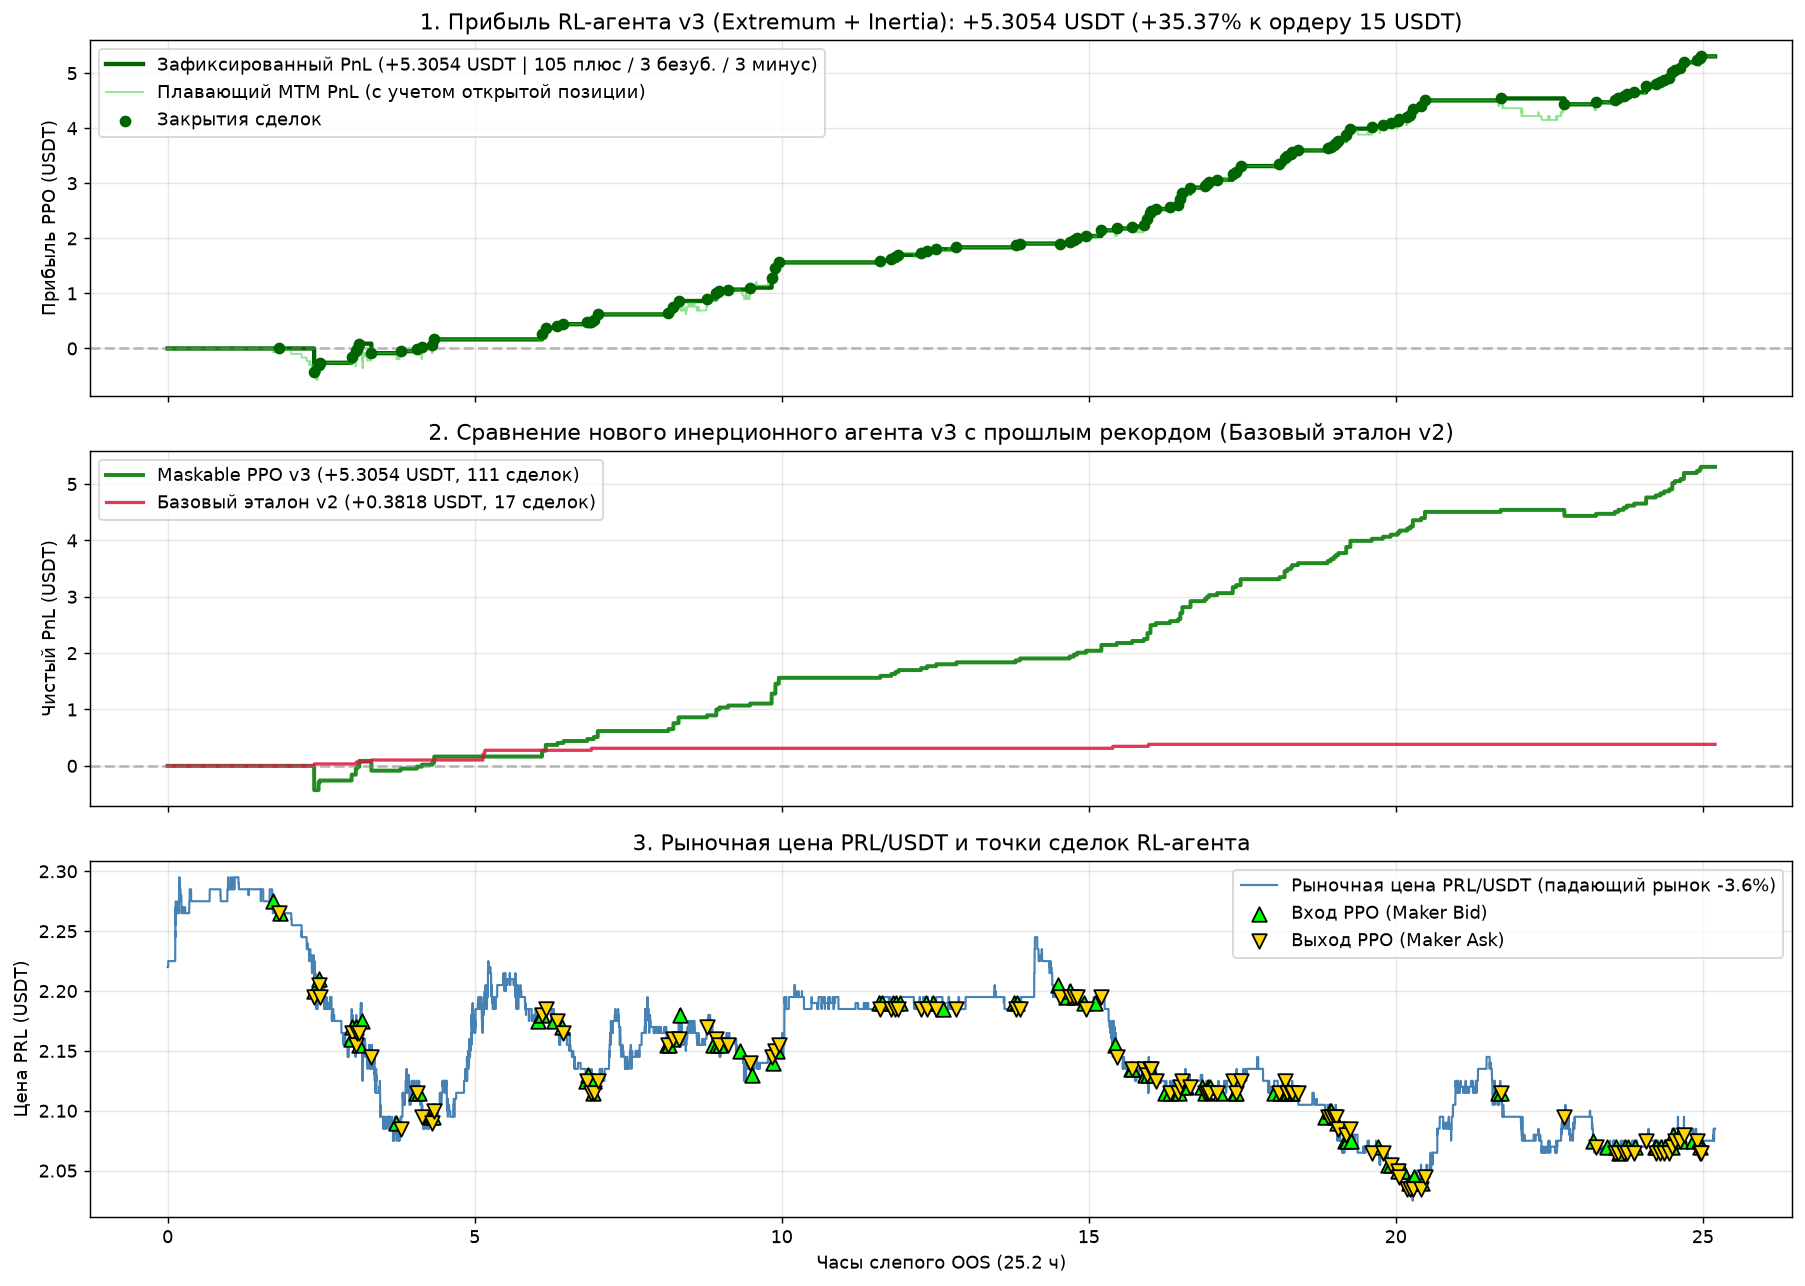


🏆 Сделки лучшей политики Maskable PPO v3 (111 шт.):


,entry_ts,exit_ts,hold_sec,entry_price,exit_action,net_pnl_usd,cum_pnl_usd
0,2026-10-22 16:23:15+03:00,2026-10-22 16:29:50+03:00,395,2.270,Maker Ask (Passive),0.0000,0.0000
1,2026-10-22 16:30:04+03:00,2026-10-22 17:03:49+03:00,2025,2.265,Maker Ask (Passive),-0.4305,-0.4305
2,2026-10-22 17:04:01+03:00,2026-10-22 17:08:09+03:00,248,2.200,Maker Ask (Passive),0.1364,-0.2941
3,2026-10-22 17:08:12+03:00,2026-10-22 17:09:12+03:00,60,2.205,Maker Ask (Passive),0.0340,-0.2601
4,2026-10-22 17:39:32+03:00,2026-10-22 17:40:27+03:00,55,2.155,Maker Ask (Passive),0.1044,-0.1557
5,2026-10-22 17:40:29+03:00,2026-10-22 17:44:30+03:00,241,2.165,Maker Ask (Passive),0.1039,-0.0518
6,2026-10-22 17:44:47+03:00,2026-10-22 17:45:40+03:00,53,2.165,Maker Ask (Passive),0.0346,-0.0171
7,2026-10-22 17:47:14+03:00,2026-10-22 17:47:57+03:00,43,2.155,Maker Ask (Passive),0.1044,0.0873
8,2026-10-22 17:50:41+03:00,2026-10-22 17:59:43+03:00,542,2.175,Maker Ask (Passive),-0.1724,-0.0851
9,2026-10-22 18:24:18+03:00,2026-10-22 18:28:17+03:00,239,2.085,Maker Ask (Passive),0.0360,-0.0491


In [2]:
# 🔍 ЯЧЕЙКА 3: Детальный слепой OOS-экзамен на 72ч полигоне (22.10.2026 14:40:38 МСК -> 23.10.2026 15:52:37 МСК)
import importlib
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)

df_ppo_trades, df_base_trades = _rl_mod.inspect_and_plot_rl_oos(coin="prl", tail_hours=72.0)
print(f"\n🏆 Сделки лучшей политики Maskable PPO ({len(df_ppo_trades)} шт.):")
display(df_ppo_trades)
print(f"\n📉 Сделки базовой эвристики ({len(df_base_trades)} шт.):")
display(df_base_trades.head(10))

⚡ Загрузка готового кэша RL-полигона (Триада H=5,12,25s): rl_triad_lob_cache_prl_24h.npz

📊 СРАВНЕНИЕ ПАСПОРТОВ КПД АГЕНТОВ НА ЧИСТОМ ФОРВАРД-ТЕСТЕ (20.33 ч | Потолок Оракула: +$4.3298 = 100% КПД)
📅 Период (МСК): 2026-10-23 15:52:38+03:00 ➔ 2026-10-24 12:12:40+03:00
Метрика КПД                        | Базовый эталон (v2)        | Maskable PPO (v3)         
------------------------------------------------------------------------------------------------
Чистый PnL (USDT / % к ордеру)     | $-0.6145 (-4.10%)        | $+4.9674 (+33.12%)
Физический КПД захвата (η_capture) | -14.19%                   | +114.73%
Интегральный индекс (Score)        |  -4.68                    | +96.18
КПД фиксации волны (η_exit от MFE) |    0.0%                   |   55.3%
Средний MFE / MAE (тики)           | 0.00т / 0.00т             | 3.23т / 1.56т
Макс. просадка MTM (MaxDD)         | $1.1205 (7.47%)         | $0.4176 (2.78%)
Profit Factor / Сделок             | PF=0.00 (1 сд.)          | PF=19.88 (78 сд.)



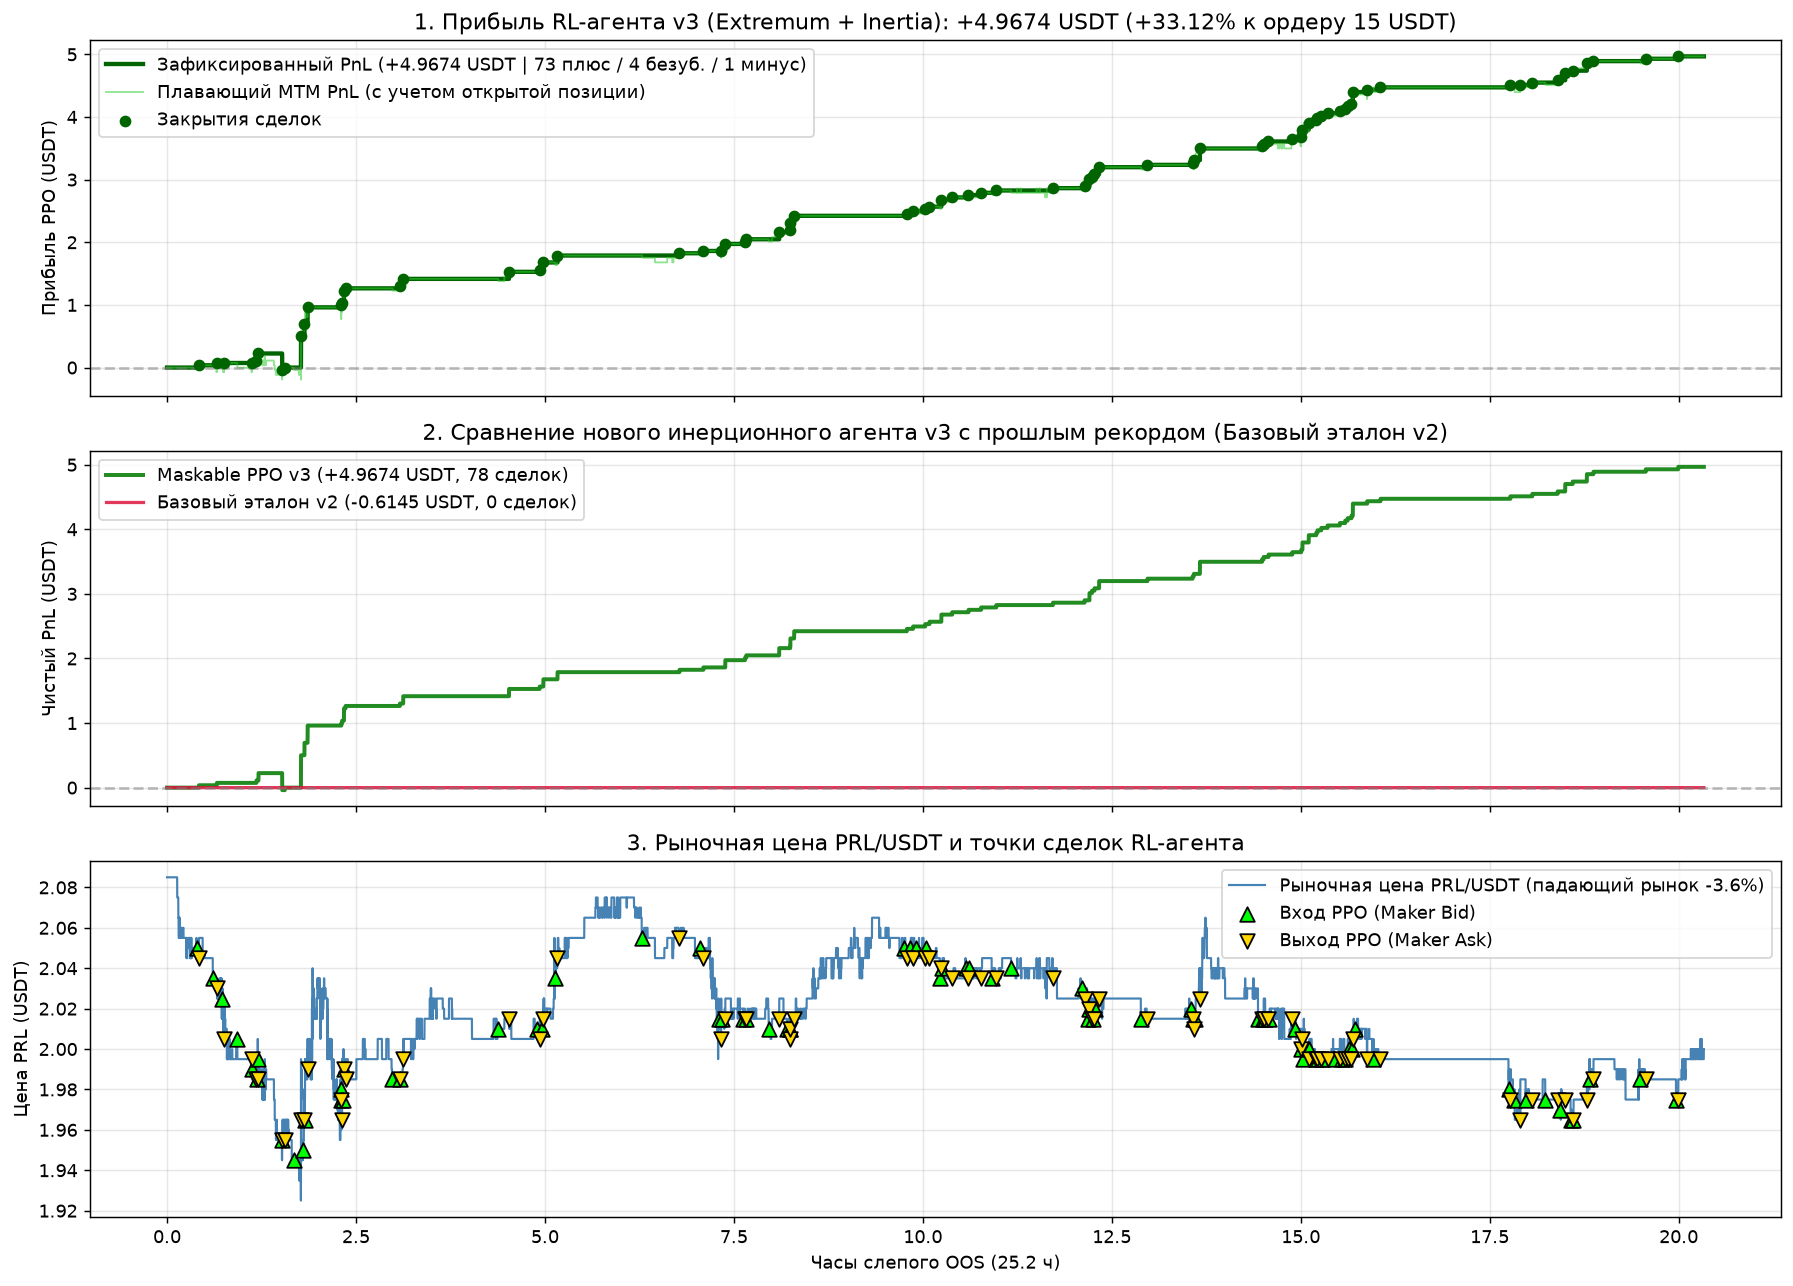


🏆 Сделки лучшей политики Maskable PPO v3 (78 шт.):


,entry_ts,exit_ts,hold_sec,entry_price,exit_action,net_pnl_usd,cum_pnl_usd
0,2026-10-23 16:16:47+03:00,2026-10-23 16:17:55+03:00,68,2.045,Maker Ask (Passive),0.0367,0.0367
1,2026-10-23 16:29:20+03:00,2026-10-23 16:32:09+03:00,169,2.035,Maker Ask (Passive),0.0369,0.0735
2,2026-10-23 16:36:16+03:00,2026-10-23 16:37:45+03:00,89,2.020,Maker Ask (Passive),0.0000,0.0735
3,2026-10-23 16:48:23+03:00,2026-10-23 16:59:50+03:00,687,2.000,Maker Ask (Passive),0.0000,0.0735
4,2026-10-23 17:00:20+03:00,2026-10-23 17:03:34+03:00,194,1.985,Maker Ask (Passive),0.0378,0.1113
5,2026-10-23 17:03:58+03:00,2026-10-23 17:05:12+03:00,74,1.985,Maker Ask (Passive),0.1134,0.2247
6,2026-10-23 17:05:13+03:00,2026-10-23 17:24:01+03:00,1128,1.995,Maker Ask (Passive),-0.2632,-0.0385
7,2026-10-23 17:24:14+03:00,2026-10-23 17:26:09+03:00,115,1.955,Maker Ask (Passive),0.0384,-0.0001
8,2026-10-23 17:33:15+03:00,2026-10-23 17:38:56+03:00,341,1.945,Maker Ask (Passive),0.5013,0.5012
9,2026-10-23 17:40:24+03:00,2026-10-23 17:41:42+03:00,78,1.945,Maker Ask (Passive),0.1928,0.6940


In [3]:
# 🚀 ЯЧЕЙКА 4: Чистый Форвард-тест на свежих данных строго после бэктеста (23.10.2026 15:52:38 МСК -> 24.10.2026 12:12:40 МСК)
import importlib
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)

df_fwd_ppo, df_fwd_base = _rl_mod.inspect_and_plot_rl_oos(
    coin="prl",
    tail_hours=24.0,
    start_ts_msk="2026-10-23 15:52:37+03:00",
)
print(f"\n🏆 Сделки на чистом Форвард-тесте Maskable PPO v3 ({len(df_fwd_ppo)} шт.):")
display(df_fwd_ppo)
print(f"\n📉 Сделки базового эталона v2 ({len(df_fwd_base)} шт.):")
display(df_fwd_base.head(10))